In [1]:
from test_beta_package import *
%matplotlib inline

In [2]:
# general check of the folder structure and assign variables
path_data_folder, path_raw_data_folder, path_process_data_folder, path_top_folder, path_info_dir, path_analysis_dir, \
path_plots_dir, path_single_pred_dir, path_multi_pred_dir = folder_structure()

In [3]:
#load the pickle files and assign dictionary to variables
data_continous_ratemaps, data_binned_glm = \
    processing_and_loading(path_raw_data_folder, path_process_data_folder, 
                           data_continous_ratemaps_pickle="rm_pre_data_diana_chasing2_notreheaded_XYZeuler_notricks_eo.pkl",
                           data_binned_glm_pickle="binned_4_GLM_rm_pre_data_diana_chasing2_notreheaded_XYZeuler_notricks_eo.pkl")


In [4]:
# obtain the information and save them for further processing
predictors_name_list, cells_id, animal_name = get_data_information(path_info_dir, data_continous_ratemaps)

In [5]:
# assign values to the model's parameters
dict_param = dict_parameters_hmm(path_info_dir, animal_name, num_dimen=1, num_categ_obs=2, N_iters=100,
                                 tolerance=10**-5, num_indep_neurons=1, num_predictors=2, max_num_states=3,
                                 observation_type="input_driven_obs",
                                 transistion_type="sticky", optim_method="em")

In [6]:
# extract the indices and totaltime from spike trains. With this function you select "num_indep_neurons" cells randomly
cell_index, tot_time = cells_selection_manual(path_info_dir, data_continous_ratemaps, data_binned_glm, dict_param, 'cells_selection.csv')


cell indices are [35]


In [7]:
# %%capture cap --no-stderr 
# processing of data and creation of instances for the inference
glmhmms_ista, process_neur, inputs_list, T_list, tot_masked_indices_list, path_plots_list, plots_folder = \
    data_structure(path_info_dir, path_analysis_dir, path_single_pred_dir, data_continous_ratemaps, data_binned_glm,
                   dict_param,
                   tot_time, cell_index, predictor_file='test_predictors.csv')

the iloc approach is 0            B Speeds
1    G Neck_elevation
2    K Ego3_Head_roll
3        N Back_pitch
4    B Speeds_1st_der
Name: Predictors', dtype: object
loading file I obtain ['B Speeds', 'G Neck_elevation', 'K Ego3_Head_roll', 'N Back_pitch', 'B Speeds_1st_der']
NAME OF THE FOLDER IS C:\Users\teof\PycharmProjects\pythonREGITglmhmm\postural_glm_hmm\results_folder\plots_dir/single_pred_dir/diana_notreheaded_singlepredictor_2022-10-26_run/
IMPORTANT: given the presence of nans (missing points of the camera) part of the data are deleted.If the number of missing points is 'small enough', it should not interfere with the inference.Below the ratio of missing points
predictor list ['B Speeds', 'G Neck_elevation', 'K Ego3_Head_roll', 'N Back_pitch', 'B Speeds_1st_der']
[nan nan nan ... nan nan nan]
[ 7.84533631  7.84695203  7.85171584 ... 11.16635283 11.18234474
 11.24178234]
!Fraction missing points is 0.005575045552201463 for the model 0 neuron 0 and predictor 0
!Fraction missing 

In [8]:
# fitting section, where you run the inference
fit_ll_states_list, glmhmms_ista, time_states_comp = inference_section(path_analysis_dir, path_info_dir, dict_param,
                                                                       glmhmms_ista=glmhmms_ista, process_neur=process_neur,
                                                                       inputs_list=inputs_list)

model state is 2
the number of prdeictor from dict is 2
number predictor is 0


  0%|          | 0/100 [00:00<?, ?it/s]

computation time loop 0 is 18.10262441635132
number predictor is 1


  0%|          | 0/100 [00:00<?, ?it/s]

computation time loop 1 is 17.566450119018555
model state is 3
the number of prdeictor from dict is 2
number predictor is 0


  0%|          | 0/100 [00:00<?, ?it/s]

computation time loop 2 is 23.73461103439331
number predictor is 1


  0%|          | 0/100 [00:00<?, ?it/s]

computation time loop 3 is 21.307003498077393
The total time for the inference is 80.71068906784058


In [9]:
# post analysis processing. Here you obtain the posterior probabilities list with structure described in the code
posterior_probs_list = posterior_prob_process(path_info_dir, path_analysis_dir, dict_param=dict_param,
                                              glmhmms_ista=glmhmms_ista, process_neur=process_neur,
                                              inputs_list=inputs_list)

the input form is [[array([[10.6933533 ,  1.        ],
       [10.94194185,  1.        ],
       [11.20825033,  1.        ],
       ...,
       [ 0.37459429,  1.        ],
       [ 0.50266247,  1.        ],
       [ 0.64292032,  1.        ]])], [array([[ 7.84533631,  1.        ],
       [ 7.84695203,  1.        ],
       [ 7.85171584,  1.        ],
       ...,
       [11.16635283,  1.        ],
       [11.18234474,  1.        ],
       [11.24178234,  1.        ]])]]
Total computation time for posterior probability is 0.399822473526001


In [10]:
# further processing of posterior to get the total occupancy for each state
states_occupancies = states_occupancies_computation(path_analysis_dir, posterior_probs_list)

[[5.41976203e-09 1.59460902e-01 8.40539093e-01]
 [4.24066846e-03 1.58812990e-01 8.36946342e-01]
 [7.97778442e-03 1.58400566e-01 8.33621649e-01]
 ...
 [5.90378113e-01 2.04296676e-01 2.05325212e-01]
 [5.86360585e-01 2.06179513e-01 2.07459902e-01]
 [5.82199432e-01 2.08138180e-01 2.09662388e-01]]


In [11]:
# Below s a sample of plots

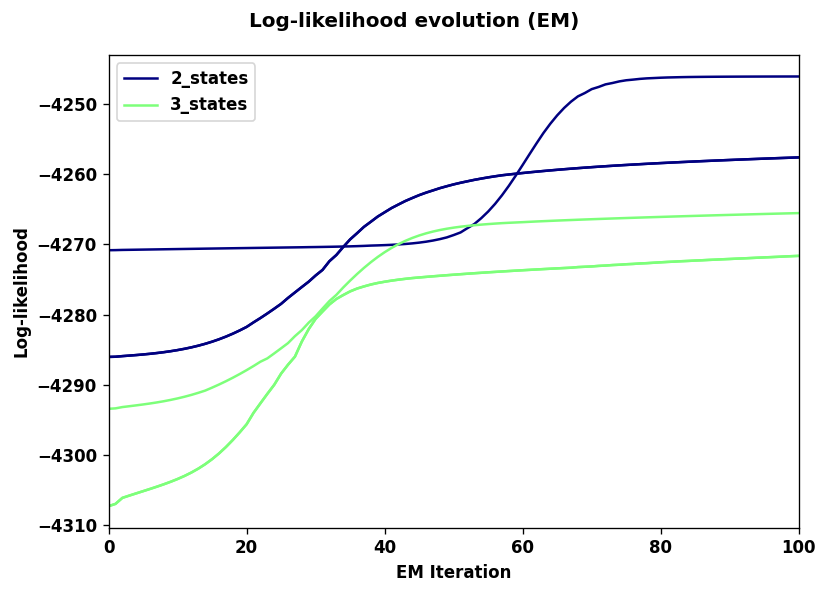

In [17]:
log_like_evolution_per_states(path_analysis_dir, path_info_dir, dict_objects=0, dict_processed_objects=0,
                              dictionary_information=0)

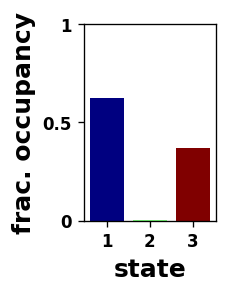

In [18]:
states_occupancies_histogram(path_analysis_dir, path_info_dir, dict_param=dict_param,
                             states_occupancies=states_occupancies)

probabilities non exponent are [[-0.01262256 -4.37857447]
 [-4.2350827  -0.01458445]]


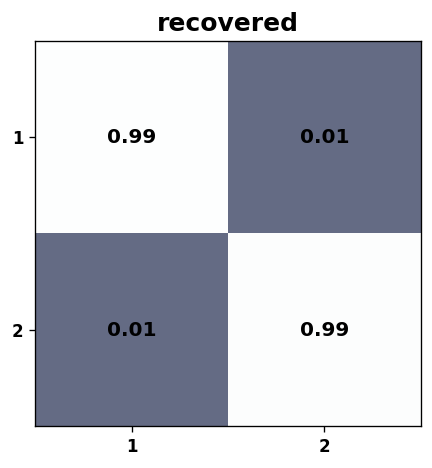

In [19]:
transition_prob_matrix(path_analysis_dir, path_info_dir, glmhmms_ista=glmhmms_ista, dict_param=dict_param)

inferred and transformed weights are {'2_states': [array([[[0.50092196, 0.98032552]],

       [[0.50775013, 0.99716421]]]), array([[[0.50525458, 0.97531224]],

       [[0.47910316, 0.99955264]]])], '3_states': [array([[[0.50675251, 0.99806205]],

       [[0.50175161, 0.9809967 ]],

       [[0.50064399, 0.98004464]]]), array([[[0.50969889, 0.97179028]],

       [[0.49271421, 0.9896431 ]],

       [[0.48344374, 0.99887579]]])]}


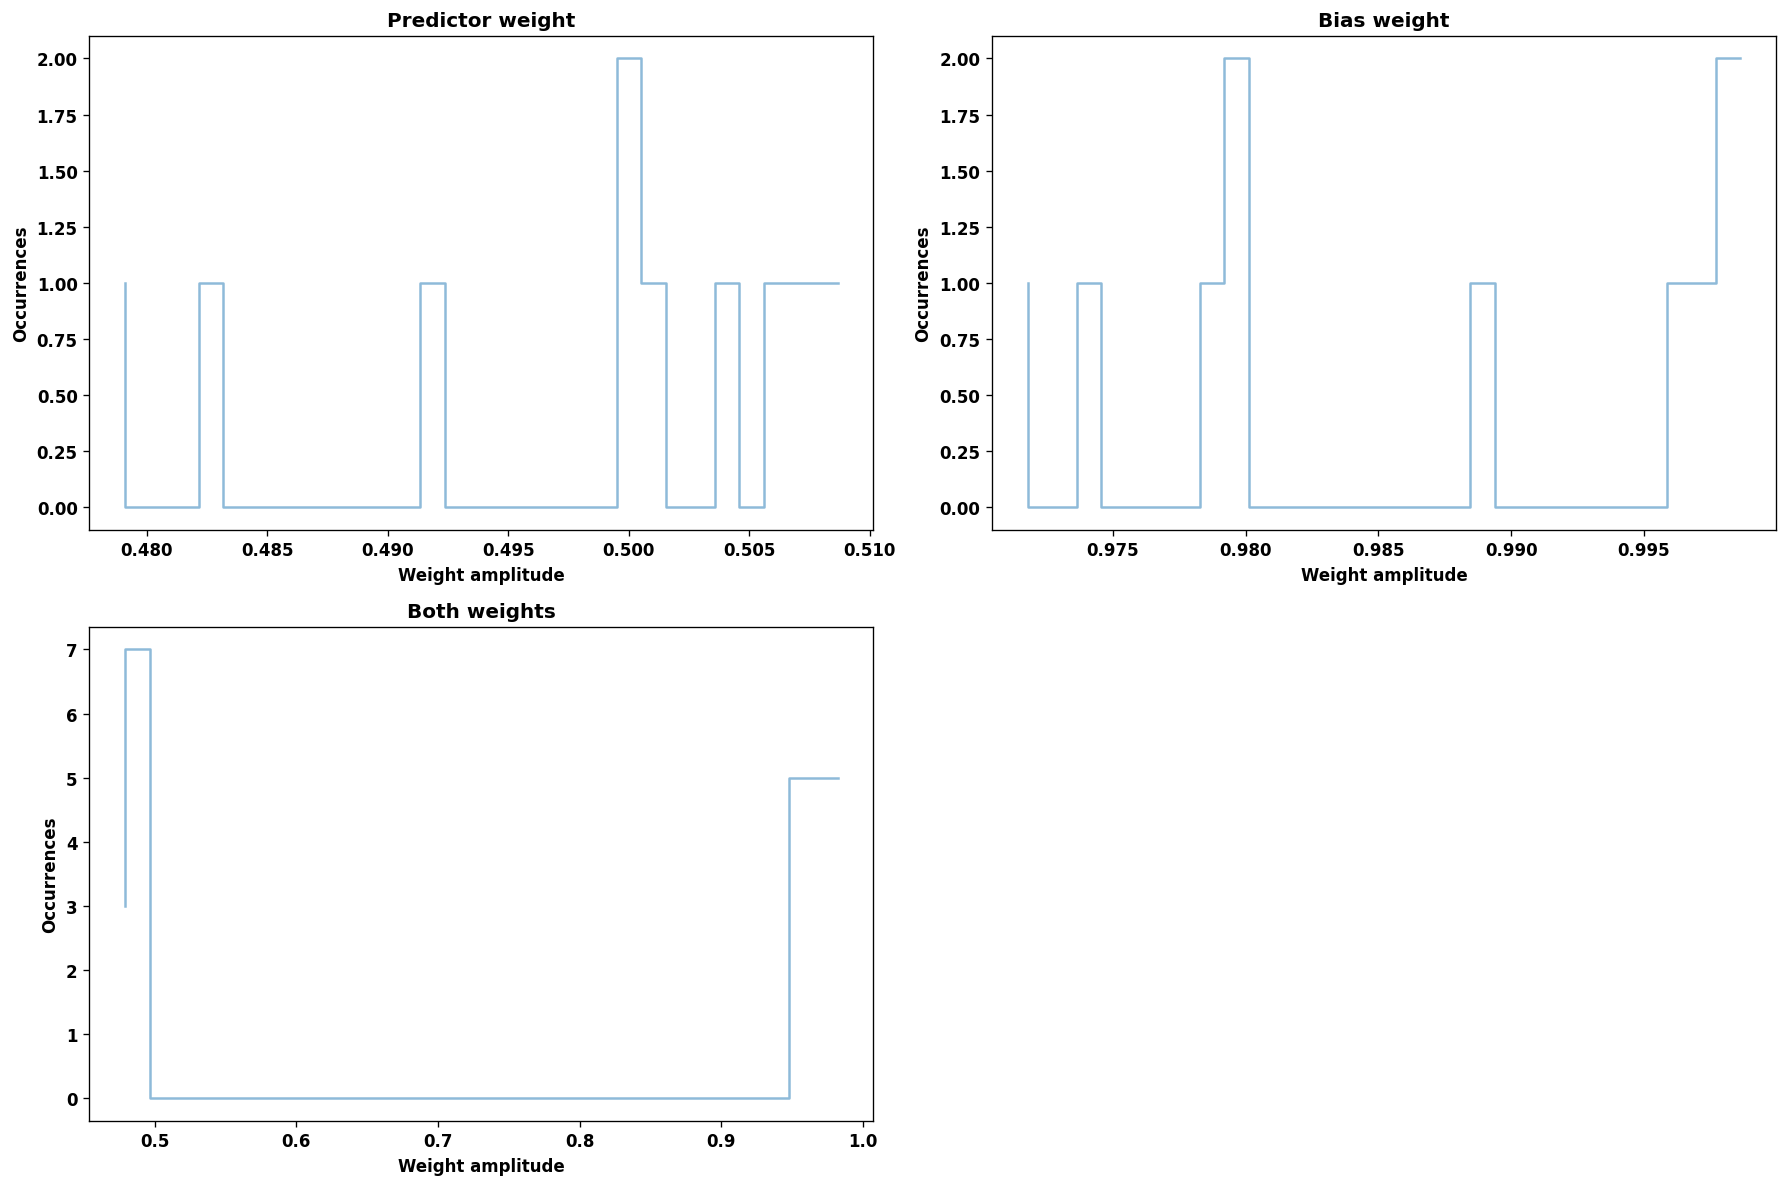

In [21]:
weights_distribution_histogram(path_analysis_dir, path_info_dir)

B Speeds
max value is 142.80865060977234
[0.07487889 0.0766196  0.07848439 ... 0.00262305 0.00351983 0.00450197]


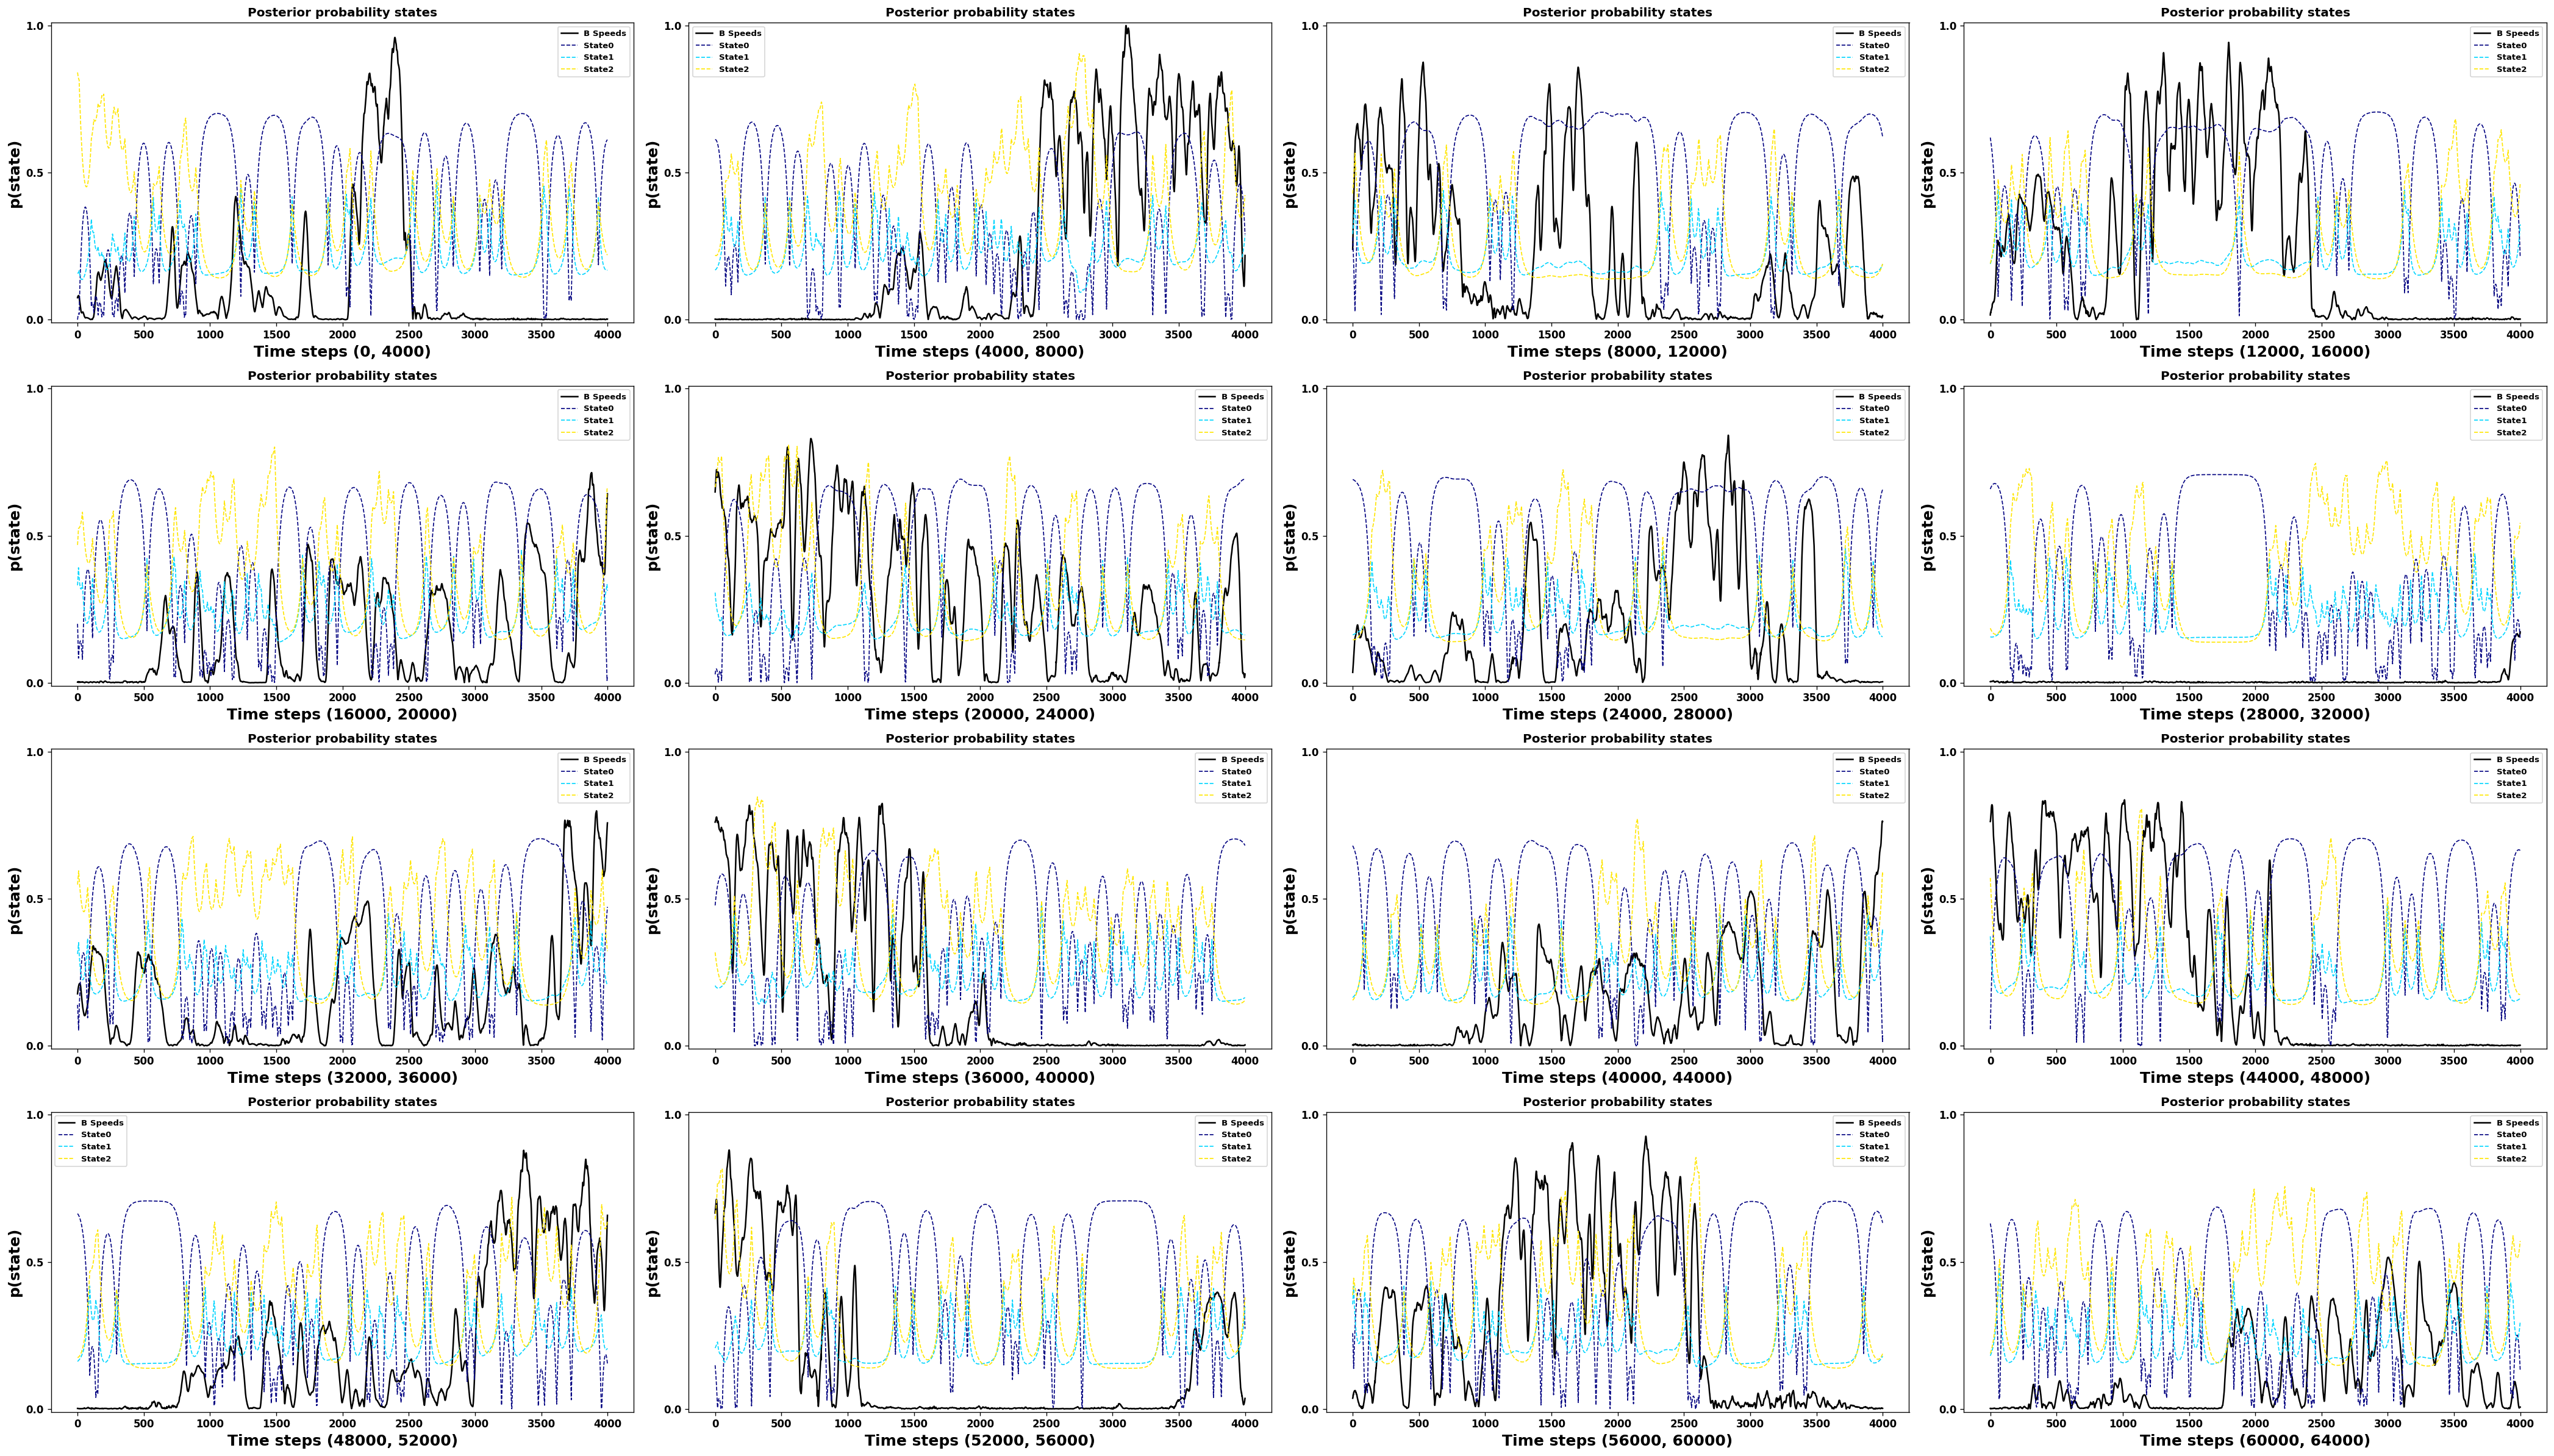

In [22]:
posterior_prob_per_states_with_predictor(path_analysis_dir, path_info_dir, data_continous_ratemaps, posterior_probs_list=posterior_probs_list,
                                             tot_masked_indices_list=tot_masked_indices_list, T_list=T_list,
                                             pred_index=0)